# Notebook 19 — Repeated Baselines and Fixed-vs-GWO LSTM Comparison
**Research objective:** Compare the two **already specified** LSTM configurations with simple baselines and quantify run-to-run variability.

**Key distinction:** This notebook compares *fixed hyperparameters* from Notebooks 13 and 14 across multiple random seeds. It **does not prove that the GWO search algorithm is superior to random search**. A search-method comparison would require equal-budget repeated GWO and random-search runs.

**Strict protocol:** train targets through 2021, validation targets 2022–2023. **Do not load 2024.** Validation was already used to choose GWO hyperparameters, so results are exploratory and selection-optimistic.

## 1. Load shared training and validation inputs

In [1]:
from pathlib import Path
import json, os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

SEED=42
ROOT=next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data'/'final'/'model_inputs').is_dir()),None)
if ROOT is None: raise FileNotFoundError('Run Notebook 12 and open the Dengue_Project folder or notebooks/ in VS Code.')
INP=ROOT/'data'/'final'/'model_inputs'; FINAL=ROOT/'data'/'final'
MODELS=ROOT/'models'; TABLES=ROOT/'results'/'tables'; FIGS=ROOT/'results'/'figures'; METRICS=ROOT/'results'/'metrics'
for folder in (TABLES,FIGS,METRICS):folder.mkdir(parents=True,exist_ok=True)
try:
 import tensorflow as tf
except ImportError as e: raise ImportError('Install tensorflow in your active .venv') from e
print('Project:',ROOT,'| TensorFlow:',tf.__version__)

def load_part(variant,part):
 path=INP/f'{variant}_{part}.npz'; meta_path=INP/f'{variant}_{part}_metadata.csv'
 if not path.is_file() or not meta_path.is_file():raise FileNotFoundError(f'Missing {path} or {meta_path}. Run Notebook 12.')
 with np.load(path,allow_pickle=False) as p:
  X=p['X'].astype(np.float32); y=p['y_raw'].astype(np.float64); ylog=p['y_log1p'].astype(np.float32); names=p['feature_names'].tolist()
 meta=pd.read_csv(meta_path,parse_dates=['target_date','feature_date','sequence_start_date'])
 assert len(X)==len(y)==len(ylog)==len(meta) and np.isfinite(X).all()
 assert meta['partition'].eq(part).all() and np.allclose(np.log1p(y),ylog,atol=1e-4)
 return X,y,ylog,names,meta

def cases(logpred):
 return np.maximum(0,np.expm1(np.clip(np.asarray(logpred,dtype=float).reshape(-1),-20,20)))
def scores(actual,pred):
 a=np.asarray(actual,float);p=np.asarray(pred,float)
 return {'MAE_cases':float(mean_absolute_error(a,p)), 'RMSE_cases':float(np.sqrt(mean_squared_error(a,p))),
         'bias_cases':float(np.mean(p-a)), 'WAPE_percent':float(100*np.sum(np.abs(a-p))/np.sum(a)) if np.sum(a)>0 else np.nan}
def build_lstm(input_shape,lr=.001,dropout=.2):
 m=tf.keras.Sequential([tf.keras.layers.Input(shape=input_shape),tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(16,activation='relu'),tf.keras.layers.Dropout(float(dropout)),tf.keras.layers.Dense(1)])
 m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=float(lr)),loss='mse')
 return m

def train_net(Xtr,ytr,Xv,yv,seed,lr=.001,dropout=.2,batch=32,epochs=40,patience=6):
 tf.keras.backend.clear_session();tf.keras.utils.set_random_seed(int(seed))
 m=build_lstm(Xtr.shape[1:],lr,dropout)
 hist=m.fit(Xtr,ytr,validation_data=(Xv,yv),epochs=int(epochs),batch_size=int(batch),
     shuffle=False,verbose=0,callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=int(patience),restore_best_weights=True)])
 return m,len(hist.history['loss'])

Project: d:\Dengue_Project | TensorFlow: 2.21.0


In [2]:
Xtr,ytr,ytrlog,names,mtr=load_part('weather_only','train')
Xv,yv,yvlog,vnames,mv=load_part('weather_only','validation')
assert names==vnames and Xtr.shape[1:]==Xv.shape[1:]
assert mtr.target_date.max()<=pd.Timestamp('2021-12-01')
assert mv.target_date.dt.year.isin([2022,2023]).all()
config_path=MODELS/'notebook13_fixed_lstm_config.json'
gwo_path=MODELS/'notebook14_gwo_search_manifest.json'
if not config_path.is_file() or not gwo_path.is_file():raise FileNotFoundError('Run Notebooks 13 and 14; their model manifests are required.')
base=json.loads(config_path.read_text(encoding='utf-8'))
gwo=json.loads(gwo_path.read_text(encoding='utf-8'))
assert gwo['test_accessed'] is False
print('Train',Xtr.shape,'| Validation',Xv.shape)
print('Fixed baseline hyperparameters:',{k:base[k] for k in ('learning_rate','dropout','batch_size')})
print('GWO-selected hyperparameters:',gwo['best_hyperparameters'])

Train (3300, 6, 33) | Validation (600, 6, 33)
Fixed baseline hyperparameters: {'learning_rate': 0.001, 'dropout': 0.2, 'batch_size': 32}
GWO-selected hyperparameters: {'learning_rate': 0.0017308560750108767, 'dropout': 0.31442572211078157, 'batch_size': 16}


## 2. Simple forecasting baselines
**Persistence:** next month equals latest known month. **Seasonal naïve:** next month equals the same month of the preceding year. **Ridge:** a regularized linear model trained on flattened six-month standardized sequences, with log1p target and train-only fitting. These benchmarks are evaluated on exactly the same validation observations as LSTM.

In [3]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
raw_path=ROOT/'data'/'processed'/'dengue_weather_monthly_2010_2024.csv'
if not raw_path.is_file():raise FileNotFoundError('Missing Notebook 09 dengue-weather monthly CSV')
raw=pd.read_csv(raw_path,parse_dates=['date'])
lookup=raw.set_index(['administrative_district','date'])['dengue_cases']
assert not lookup.index.duplicated().any()

def historical_prediction(meta,months_back):
 keys=pd.MultiIndex.from_arrays([meta.administrative_district.to_numpy(),
     (meta.target_date-pd.DateOffset(months=months_back)).to_numpy()],names=['administrative_district','date'])
 values=lookup.reindex(keys).to_numpy(dtype=float)
 if not np.isfinite(values).all():raise ValueError('Missing baseline history; check source data.')
 return values
simple_preds={'persistence_last_month':historical_prediction(mv,1),
              'seasonal_naive_12_months':historical_prediction(mv,12)}
linear=Ridge(alpha=10.0)
linear.fit(Xtr.reshape(len(Xtr),-1),ytrlog)
simple_preds['ridge_flattened_6m']=cases(linear.predict(Xv.reshape(len(Xv),-1)))
base_rows=[];prediction_rows=[]
for label,pred in simple_preds.items():
 base_rows.append({'model':label,'seed':'deterministic','n_train':len(Xtr),'n_val':len(Xv),**scores(yv,pred)})
 out=mv[['administrative_district','target_date']].copy();out['model']=label;out['seed']='deterministic';out['actual_cases']=yv;out['predicted_cases']=pred
 prediction_rows.append(out)
baselines=pd.DataFrame(base_rows)
display(baselines)

,model,seed,n_train,n_val,MAE_cases,RMSE_cases,bias_cases,WAPE_percent
0,persistence_last_month,deterministic,3300,600,77.130476,170.158789,-15.833809,43.613148
1,seasonal_naive_12_months,deterministic,3300,600,118.018095,257.721499,-90.552857,66.732905
2,ridge_flattened_6m,deterministic,3300,600,116.960983,233.531818,-107.440437,66.135165


## 3. Repeat the two LSTM configurations with matched random seeds
Both networks use the same architecture and epoch/patience limits. Each seed is applied to both configurations. This measures **initialization/training variability**, not variability of the GWO optimization search itself. Training may take time on a laptop.

In [4]:
SEEDS=(42,123,2026)  # use (42,) for a smoke test; >=3 recommended for paper
configs={
 'fixed_lstm':{'lr':float(base['learning_rate']),'dropout':float(base['dropout']),'batch':int(base['batch_size'])},
 'gwo_selected_lstm':{'lr':float(gwo['best_hyperparameters']['learning_rate']),
                      'dropout':float(gwo['best_hyperparameters']['dropout']),
                      'batch':int(gwo['best_hyperparameters']['batch_size'])}}
MAX_EPOCHS=int(base['max_epochs']);PATIENCE=int(base['early_stopping_patience'])
assert MAX_EPOCHS==int(gwo['max_epochs']) and PATIENCE==int(gwo['patience'])
model_rows=[]
for seed in SEEDS:
 for label,cfg in configs.items():
  net,epochs=train_net(Xtr,ytrlog,Xv,yvlog,seed,lr=cfg['lr'],dropout=cfg['dropout'],batch=cfg['batch'],epochs=MAX_EPOCHS,patience=PATIENCE)
  pred=cases(net.predict(Xv,verbose=0))
  row={'model':label,'seed':seed,'n_train':len(Xtr),'n_val':len(Xv),'epochs':epochs,**scores(yv,pred)}
  model_rows.append(row)
  out=mv[['administrative_district','target_date']].copy();out['model']=label;out['seed']=seed;out['actual_cases']=yv;out['predicted_cases']=pred
  prediction_rows.append(out)
  print(label,'seed',seed,'MAE',round(row['MAE_cases'],2),'RMSE',round(row['RMSE_cases'],2),'epochs',epochs)
  del net
repeats=pd.DataFrame(model_rows);all_preds=pd.concat(prediction_rows,ignore_index=True)
display(repeats)


fixed_lstm seed 42 MAE 89.08 RMSE 177.53 epochs 40
gwo_selected_lstm seed 42 MAE 85.06 RMSE 178.24 epochs 21
fixed_lstm seed 123 MAE 86.5 RMSE 177.51 epochs 39
gwo_selected_lstm seed 123 MAE 85.31 RMSE 169.55 epochs 25
fixed_lstm seed 2026 MAE 83.91 RMSE 167.35 epochs 40
gwo_selected_lstm seed 2026 MAE 82.62 RMSE 163.15 epochs 27


,model,seed,n_train,n_val,epochs,MAE_cases,RMSE_cases,bias_cases,WAPE_percent
0,fixed_lstm,42,3300,600,40,89.078628,177.532125,-52.342482,50.369188
1,gwo_selected_lstm,42,3300,600,21,85.064860,178.239409,-46.661513,48.099617
2,fixed_lstm,123,3300,600,39,86.500694,177.510924,-52.513666,48.911505
3,gwo_selected_lstm,123,3300,600,25,85.312895,169.553258,-12.424709,48.239867
4,fixed_lstm,2026,3300,600,40,83.907979,167.353868,-39.892400,47.445463
5,gwo_selected_lstm,2026,3300,600,27,82.622743,163.149672,-10.979109,46.718731


## 4. Report run-to-run variability and paired differences
Positive `fixed_minus_GWO` indicates lower GWO MAE for that seed. Standard deviation across a few seeds is descriptive, not proof of statistical significance.

Fixed minus GWO paired validation MAE by seed:


model,fixed_lstm,gwo_selected_lstm,fixed_minus_GWO_MAE
seed,,,
42,89.078628,85.064860,4.013768
123,86.500694,85.312895,1.187800
2026,83.907979,82.622743,1.285235


Repeated LSTM summary:


,model,n_seeds,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,bias_mean
0,fixed_lstm,3,86.495767,2.585328,174.132306,5.870309,-48.249516
1,gwo_selected_lstm,3,84.333499,1.486739,170.314113,7.573587,-23.355110


Simple baselines:


,model,seed,n_train,n_val,MAE_cases,RMSE_cases,bias_cases,WAPE_percent
0,persistence_last_month,deterministic,3300,600,77.130476,170.158789,-15.833809,43.613148
1,seasonal_naive_12_months,deterministic,3300,600,118.018095,257.721499,-90.552857,66.732905
2,ridge_flattened_6m,deterministic,3300,600,116.960983,233.531818,-107.440437,66.135165


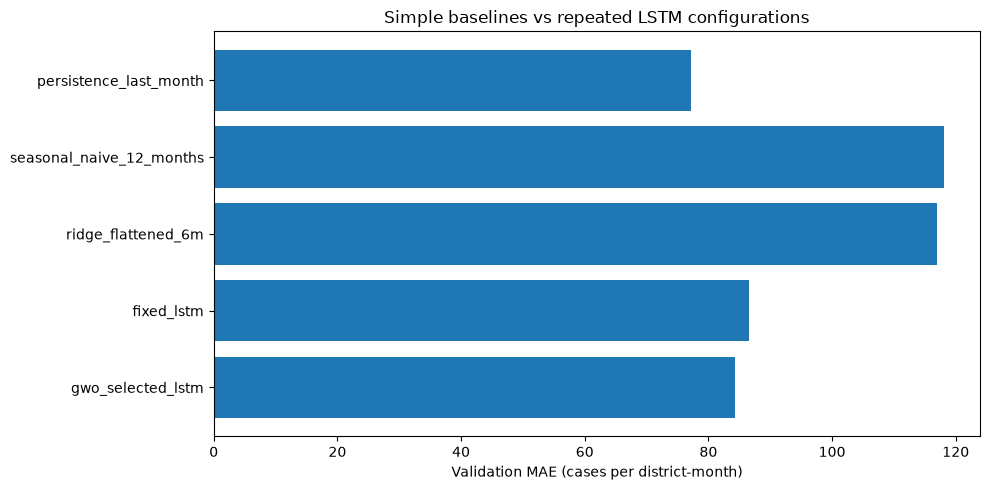

In [5]:
summary=(repeats.groupby('model',as_index=False).agg(n_seeds=('seed','nunique'),
 MAE_mean=('MAE_cases','mean'),MAE_sd=('MAE_cases','std'),RMSE_mean=('RMSE_cases','mean'),RMSE_sd=('RMSE_cases','std'),bias_mean=('bias_cases','mean')))
paired=repeats.pivot(index='seed',columns='model',values='MAE_cases')
paired['fixed_minus_GWO_MAE']=paired['fixed_lstm']-paired['gwo_selected_lstm']
print('Fixed minus GWO paired validation MAE by seed:');display(paired)
print('Repeated LSTM summary:');display(summary)
print('Simple baselines:');display(baselines)
plot=pd.concat([baselines[['model','MAE_cases']].rename(columns={'MAE_cases':'MAE_mean'}),summary[['model','MAE_mean']]])
fig,ax=plt.subplots(figsize=(10,5));ax.barh(plot.model,plot.MAE_mean);ax.invert_yaxis()
ax.set(xlabel='Validation MAE (cases per district-month)',title='Simple baselines vs repeated LSTM configurations')
fig.tight_layout();fig.savefig(FIGS/'notebook19_validation_baseline_comparison.png',dpi=160);plt.show()

## 5. Exploratory paired month-block bootstrap
District-month observations within the same calendar month are correlated. We therefore resample **whole validation target months** (24 month blocks), not 600 individual rows, to estimate uncertainty in the paired difference for one chosen seed. The interval is descriptive only because model selection and early stopping already used this validation window.

In [6]:
BOOT_SEED=int(SEEDS[0]);N_BOOT=1000
fixed=all_preds.loc[(all_preds.model=='fixed_lstm')&(all_preds.seed==BOOT_SEED)].sort_values(['administrative_district','target_date'])
gw=all_preds.loc[(all_preds.model=='gwo_selected_lstm')&(all_preds.seed==BOOT_SEED)].sort_values(['administrative_district','target_date'])
assert fixed[['administrative_district','target_date']].reset_index(drop=True).equals(gw[['administrative_district','target_date']].reset_index(drop=True))
paired_obs=fixed[['administrative_district','target_date','actual_cases','predicted_cases']].rename(columns={'predicted_cases':'fixed_pred'}).reset_index(drop=True)
paired_obs['gwo_pred']=gw.predicted_cases.to_numpy()
paired_obs['fixed_abs_error']=np.abs(paired_obs.fixed_pred-paired_obs.actual_cases)
paired_obs['gwo_abs_error']=np.abs(paired_obs.gwo_pred-paired_obs.actual_cases)
month_diff=paired_obs.groupby('target_date').apply(lambda d:float(np.mean(d.fixed_abs_error-d.gwo_abs_error)),include_groups=False)
assert len(month_diff)==24
rng=np.random.default_rng(1001)
boot=np.array([rng.choice(month_diff.to_numpy(),size=len(month_diff),replace=True).mean() for _ in range(N_BOOT)])
ci=np.quantile(boot,[.025,.975]); observed=float(month_diff.mean())
print(f'Paired fixed-minus-GWO MAE: {observed:.3f} cases')
print(f'Exploratory 95% month-block bootstrap interval: [{ci[0]:.3f}, {ci[1]:.3f}] cases')
print('Caution: this is not a post-selection confirmatory confidence interval.')

Paired fixed-minus-GWO MAE: 4.014 cases
Exploratory 95% month-block bootstrap interval: [-0.030, 8.311] cases
Caution: this is not a post-selection confirmatory confidence interval.


## 6. Save complete results and transparent protocol

In [7]:
baselines.to_csv(TABLES/'notebook19_simple_baselines.csv',index=False)
repeats.to_csv(TABLES/'notebook19_repeated_lstm_metrics.csv',index=False)
summary.to_csv(TABLES/'notebook19_repeated_lstm_summary.csv',index=False)
paired.to_csv(TABLES/'notebook19_paired_seed_differences.csv')
all_preds.to_csv(TABLES/'notebook19_validation_predictions.csv',index=False)
pd.DataFrame({'boot_fixed_minus_GWO_MAE':boot}).to_csv(TABLES/'notebook19_month_block_bootstrap.csv',index=False)
protocol={'data_variant':'weather_only','train_target_end':'2021-12','validation_target_period':'2022-2023',
 'test_2024_accessed':False,'seeds':list(SEEDS),'fixed_hyperparameters':configs['fixed_lstm'],
 'gwo_selected_hyperparameters':configs['gwo_selected_lstm'],'gwo_search_repeated':False,
 'epochs_max':MAX_EPOCHS,'patience':PATIENCE,'bootstrap_seed':BOOT_SEED,'bootstrap_month_blocks':24,
 'bootstrap_interval_95':ci.tolist(),'validation_post_selection_warning':True}
(METRICS/'notebook19_repeated_comparison_protocol.json').write_text(json.dumps(protocol,indent=2),encoding='utf-8')
print('Saved Notebook 19 figures, metrics, predictions, and protocol.')

Saved Notebook 19 figures, metrics, predictions, and protocol.


## 7. Conclusions you may and may not claim
**Supported after execution:** relative validation MAE of naïve forecasts, ridge, fixed LSTM and GWO-selected LSTM; sensitivity to random training seeds; exploratory paired differences.

**Not supported by this notebook:** superiority of the GWO *algorithm* over random search; superiority on a new independent test; statistical significance based on treating 600 district-months as independent; prediction of an entire future year without updated observed history.

For a rigorous optimizer study, rerun the **GWO search itself** across multiple seeds and compare to equal-budget random search under nested chronological validation. Because 2024 has already been inspected, keep the additional analysis explicitly exploratory or obtain a later untouched temporal holdout.